# Importance sampling

Estimate $I = \int_0^1 e^{-x^2}\,dx $ with Monte Carlo.

## Task 1: uniform sampling

$I \approx \frac{1}{N}\sum_i f(x_i)$ with $x_i \sim U(0,1)$; the error is $\sigma/\sqrt{N}$.

In [ ]:
using Statistics

# Number of Monte Carlo samples and integration bounds
N_POINTS = 1000
BOUNDRY = (0, 1)

# Generate N independent samples from the uniform distribution U(0, 1)
sampled_points_uniform = rand(N_POINTS)

# Evaluate the integrand f(x) = exp(-x²) at each sampled point
resolutions_uniform = exp.(-(sampled_points_uniform.^2))

# Estimate the expected value E[f(X)] using the sample mean
avg_solution_uniform = mean(resolutions_uniform)

# Estimate the integral as the interval length multiplied by the sample mean
estimate_solution_uniform = (BOUNDRY[2] - BOUNDRY[1]) * avg_solution_uniform

# Estimate the standard error of the Monte Carlo estimator
standard_error_uniform = (BOUNDRY[2] - BOUNDRY[1]) * std(resolutions_uniform) / sqrt(N_POINTS)

# Display the estimated integral and its standard error (± 1 SE)
println("solution for $N_POINTS uniformly sampled points: $estimate_solution_uniform ± $standard_error_uniform")

solution for 1000 uniformly sampled points: 0.7511235115700208 ± 0.006324880634676812


## Task 2: importance sampling

Sample from $g(x) = e^{-x}/(1-e^{-1})$, which roughly follows the shape of $f$, and average $f/g$. Samples from $g$ are drawn by rejection sampling.

In [16]:
using Statistics

# Define the normalized importance sampling probability density g(x)
function g(x)
    return exp(-x) / (1 - exp(-1))
end

# Generate N_POINTS samples from g(x) using rejection sampling
samples_importance = Float64[]
g_max = g(0)

while length(samples_importance) < N_POINTS
    x = rand()
    y = rand() * g_max

    # Accept the sample if the point lies below g(x)
    if y <= g(x)
        push!(samples_importance, x)
    end
end

# Evaluate the weighted integrand f(x) / g(x) for each accepted sample
resolutions_importance = exp.(-(samples_importance.^2)) ./ g.(samples_importance)

# Estimate the integral using the mean of the weighted samples
avg_solution_importance = mean(resolutions_importance)

# Estimate the standard error of the importance sampling estimator
standard_error_importance = std(resolutions_importance) / sqrt(N_POINTS)

# Display the estimated integral and its standard error (± 1 SE)
println("Solution for $N_POINTS importance-sampled points: $avg_solution_importance ± $standard_error_importance")

Solution for 1000 importance-sampled points: 0.7474538594035586 ± 0.0017383693414613826


## Comparing the two methods

Same code wrapped into functions, so it can be run for different $N$.

In [17]:
using Statistics
using Random
using Plots

# Define the normalized importance sampling density
function g(x)
    return exp(-x) / (1 - exp(-1))
end

# Standard Monte Carlo with uniform sampling
function uniform_mc(N_POINTS)
    sampled_points = rand(N_POINTS)

    resolutions = exp.(-(sampled_points.^2))

    estimate = mean(resolutions)
    standard_error = std(resolutions) / sqrt(N_POINTS)

    return estimate, standard_error
end

# Monte Carlo with importance sampling
function importance_mc(N_POINTS)
    samples = Float64[]
    g_max = g(0)

    # Generate samples using rejection sampling
    while length(samples) < N_POINTS
        x = rand()
        y = rand() * g_max

        if y <= g(x)
            push!(samples, x)
        end
    end

    # Evaluate the weighted integrand
    resolutions = exp.(-(samples.^2)) ./ g.(samples)

    estimate = mean(resolutions)
    standard_error = std(resolutions) / sqrt(N_POINTS)

    return estimate, standard_error
end


importance_mc (generic function with 1 method)

Standard error vs. $N$ for both methods (log-log).

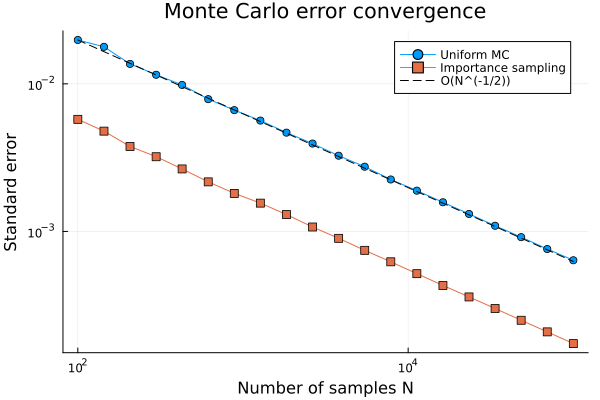

In [ ]:

# Define sample sizes on a logarithmic scale
N_values = round.(Int, 10 .^ range(2, 5, length=20))

# Store standard errors for both methods
errors_uniform = Float64[]
errors_importance = Float64[]

# Run both estimators for increasing sample sizes
for N in N_values
    _, se_uniform = uniform_mc(N)
    _, se_importance = importance_mc(N)

    push!(errors_uniform, se_uniform)
    push!(errors_importance, se_importance)
end



plot(
    N_values,
    errors_uniform,
    xscale=:log10,
    yscale=:log10,
    label="Uniform MC",
    marker=:circle,
    xlabel="Number of samples N",
    ylabel="Standard error",
    title="Monte Carlo error convergence"
)

plot!(N_values, errors_importance, label="Importance sampling", marker=:square)

# Reference convergence rate: O(N^(-1/2))
reference = errors_uniform[1] .* sqrt.(N_values[1] ./ N_values)

plot!(N_values, reference, label="O(N^(-1/2))", linestyle=:dash, color=:black)